# Hizmet Sağlayıcı Eşleştirme Aracı

YetGen Core Python Programı bitirme projesi.

Farklı Excel sayfalarında duran firma bilgilerini tek bir tabloda topluyor, kullanıcıya hizmet alanı, bölge ve sektör seçtiriyor ve bu seçimlere uyan firmaları referans ve iletişim bilgileriyle listeliyor. Sonunda bulunan firmaları karşılaştıran bir grafik çiziyor.

In [1]:
import pandas as pd  # Excel dosyasını okumak ve veriyi tablo halinde işlemek için
import matplotlib.pyplot as plt  # Sonuçları grafikle göstermek için

# Excel dosyasını yüklüyoruz. Dosya bulunamazsa veya okunamazsa anlaşılır bir hata veriyoruz.
dosya_yolu = "data.xlsx"
try:
    xls = pd.ExcelFile(dosya_yolu)
except FileNotFoundError:
    raise SystemExit(f"Hata: {dosya_yolu} dosyası bulunamadı.")
except Exception as e:
    raise SystemExit(f"Excel dosyası okunurken bir hata oluştu: {e}")

In [2]:
# Her firma ayrı bir sayfada duruyor. Bütün sayfaları tek bir tabloda topluyoruz.
sayfalar = []
for sayfa_adi in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sayfa_adi)
    df.columns = df.columns.str.strip()  # Sütun adlarındaki fazla boşlukları temizliyoruz
    if 'ŞİRKET ADI' not in df.columns:
        df['ŞİRKET ADI'] = sayfa_adi  # Şirket adı yoksa sayfa adını kullanıyoruz
    sayfalar.append(df)

tum_veri = pd.concat(sayfalar, ignore_index=True)
print("Veri yüklendi. Toplam firma sayısı:", len(tum_veri))

Veri yüklendi. Toplam firma sayısı: 17


In [3]:
def parcala(metin):
    """Virgülle ayrılmış bir hücreyi temiz bir listeye çevirir."""
    if pd.isna(metin):
        return []
    return [parca.strip() for parca in str(metin).split(',') if parca.strip()]


class VeriFiltreleyici:
    def __init__(self, veri):
        self.veri = veri

    def secenekleri_getir(self, sutun_adi):
        """Bir sütundaki bütün değerleri tekrarsız ve alfabetik olarak döndürür."""
        elemanlar = set()
        for hucre in self.veri[sutun_adi]:
            elemanlar.update(parcala(hucre))
        return sorted(elemanlar)

    def eslesen_sirketleri_bul(self, hizmetler, bolgeler, sektor):
        """Seçilen hizmetlerden en az birini, bölgelerden en az birini ve seçilen sektörü karşılayan firmaları bulur."""
        print(f"Aranan -> Hizmet: {', '.join(hizmetler)} | Bölge: {', '.join(bolgeler)} | Sektör: {sektor}")

        def uygun_mu(satir):
            # Her kriteri kendi sütununda ve birebir eşleşmeyle arıyoruz.
            # Böylece örneğin 'Asya' seçildiğinde 'Orta Asya' yanlışlıkla eşleşmiyor.
            hizmet_uygun = any(h in parcala(satir['HİZMET VERİLEN ALANLAR']) for h in hizmetler)
            bolge_uygun = any(b in parcala(satir['BÖLGE']) for b in bolgeler)
            sektor_uygun = sektor in parcala(satir['SEKTÖRLER'])
            return hizmet_uygun and bolge_uygun and sektor_uygun

        return self.veri[self.veri.apply(uygun_mu, axis=1)]


def menuyu_goster():
    print("\n------------------HOŞ GELDİNİZ--------------------")
    print("Size en uygun firmayı önerebilmemiz için menüden seçimlerinizi yapınız.")
    input("Başlamak için Enter'a basınız.")


def secim_al(secenekler, mesaj, tek_secim=False):
    """Kullanıcıdan bir veya birden fazla seçim alır. En az bir seçim yapılmadan devam etmez."""
    print(f"\n{mesaj}")
    for i, secenek in enumerate(secenekler, 1):
        print(f"{i}. {secenek}")

    secimler = []
    while True:
        if tek_secim:
            giris = input("Seçiminizin numarasını giriniz: ")
        else:
            giris = input("Seçiminizin numarasını giriniz (birden fazla seçim için virgülle ayırın, bitirmek için 'q' yazın): ")

        if giris.strip().lower() == 'q':
            if secimler:
                break
            print("En az bir seçim yapmalısınız.")
            continue

        try:
            numaralar = [int(s.strip()) for s in giris.split(',')]
        except ValueError:
            print("Geçersiz giriş. Lütfen sayı giriniz.")
            continue

        gecerli = [secenekler[n - 1] for n in numaralar if 1 <= n <= len(secenekler)]
        if not gecerli:
            print("Listede olmayan bir numara girdiniz.")
            continue

        for secenek in gecerli:
            if secenek not in secimler:
                secimler.append(secenek)
        print(f"Şu ana kadar seçtikleriniz: {', '.join(secimler)}")

        if tek_secim:
            secimler = secimler[:1]
            break

    return secimler

In [4]:
def sirketleri_karsilastir(veri):
    """Bulunan firmaların referans, hizmet alanı, sektör ve bölge sayılarını yan yana gösterir."""
    sirketler = veri['ŞİRKET ADI'].tolist()
    olcutler = {
        'Referans Sayısı': 'REFERANSLAR',
        'Hizmet Alanı Sayısı': 'HİZMET VERİLEN ALANLAR',
        'Sektör Sayısı': 'SEKTÖRLER',
        'Bölge Sayısı': 'BÖLGE',
    }

    x = range(len(sirketler))
    genislik = 0.2
    fig, ax = plt.subplots(figsize=(max(8, len(sirketler) * 2), 5))

    for j, (etiket, sutun) in enumerate(olcutler.items()):
        sayilar = [len(parcala(h)) for h in veri[sutun]]
        konum = [i + (j - 1.5) * genislik for i in x]
        ax.bar(konum, sayilar, genislik, label=etiket)

    ax.set_ylabel('Sayı')
    ax.set_title('Bulunan Firmaların Karşılaştırması')
    ax.set_xticks(list(x))
    ax.set_xticklabels(sirketler, rotation=30, ha='right')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()


------------------HOŞ GELDİNİZ--------------------
Size en uygun firmayı önerebilmemiz için menüden seçimlerinizi yapınız.
Başlamak için Enter'a basınız.

Hizmet almak istediğiniz alanları seçiniz:
1. Dijital Pazarlama Danışmanlığı
2. Dönüşüm Optimizasyonu
3. E-Ticaret Danışmanlığı
4. E-posta Pazarlama
5. Finans Yönetimi
6. Google Reklam Danışmanlığı
7. Influencer Marketing
8. Kurumsal Hizmet Yönetimi
9. Marka Yönetimi
10. Mobil Uygulama Geliştiriciliği
11. Müşteri İlişkileri Yönetimi
12. Pazar Analizi/Rakip Analizi/Veri Analizi
13. Pazarlama Yönetimi
14. Proje Yönetimi
15. Raporlama Otomasyonu
16. Reklam Yönetimi
17. Robotik Süreç Otomasyonu
18. Rota Optimizasyonu
19. SEO Danışmanlığı
20. Satış Danışmanlığı
21. Sosyal Medya Danışmanlığı
22. Sosyal Medya Yönetimi
23. Stok/Satış/Sipariş Yönetimi
24. Veri Yönetimi
25. Web Analizi
26. Web Tasarım/Geliştirme
27. İlişkilendirme Modelleri
28. İş Süreçleri Otomasyonu
Seçiminizin numarasını giriniz (birden fazla seçim için virgülle ayırın, bi

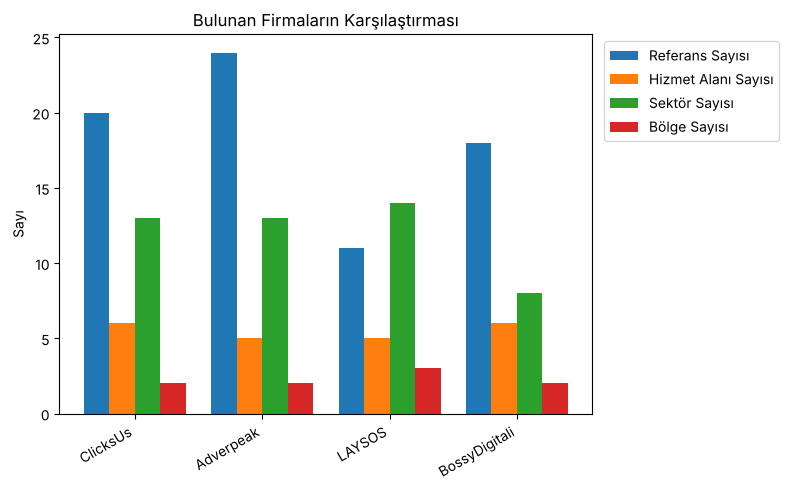

In [5]:
# Program akışı
menuyu_goster()
filtreleyici = VeriFiltreleyici(tum_veri)

hizmet_secimleri = secim_al(filtreleyici.secenekleri_getir('HİZMET VERİLEN ALANLAR'),
                            "Hizmet almak istediğiniz alanları seçiniz:")
bolge_secimleri = secim_al(filtreleyici.secenekleri_getir('BÖLGE'),
                           "Hizmet almak istediğiniz bölgeleri seçiniz:")
sektor_secimi = secim_al(filtreleyici.secenekleri_getir('SEKTÖRLER'),
                         "Faaliyet gösterdiğiniz sektörü seçiniz:", tek_secim=True)[0]

sonuc = filtreleyici.eslesen_sirketleri_bul(hizmet_secimleri, bolge_secimleri, sektor_secimi)

print("\nSonuç:")
if sonuc.empty:
    print("Seçtiğiniz kriterlerin tümünü karşılayan bir firma bulunamadı. Farklı seçimlerle tekrar deneyebilirsiniz.")
else:
    print(f"{len(sonuc)} firma bulundu.")
    for i, (_, firma) in enumerate(sonuc.iterrows(), 1):
        print(f"\n{i}. {firma['ŞİRKET ADI']}")
        for baslik, sutun in [('Referanslar', 'REFERANSLAR'), ('İletişim', 'İLETİŞİM'), ('Sektörler', 'SEKTÖRLER')]:
            print(f"   {baslik}:")
            for parca in parcala(firma[sutun]):
                print(f"   - {parca}")

    sirketleri_karsilastir(sonuc)